In [1]:
import pandas as pd
df = pd.read_csv("df_clustering.csv")

In [2]:
df.head()

,time,cpu_user,cpu_system,memoria_used,disco_used_frac,red_bytes_s,tasa_llamadas_pedidos,tasa_llamadas_catalogo,perfil
0,2026-10-06 00:20:00+00:00,0.197000,0.038000,0.218574,0.148526,25491.115395,24.299558,47.499136,Operación normal
1,2026-10-06 00:20:10+00:00,0.210059,0.040434,0.218544,0.148527,24661.480395,33.301280,62.002382,Operación normal
2,2026-10-06 00:20:20+00:00,0.173695,0.037149,0.217593,0.148527,17657.556489,18.800486,39.001008,Operación normal
3,2026-10-06 00:20:30+00:00,0.192385,0.038076,0.218207,0.148527,23276.729134,25.300219,48.500420,Operación normal
4,2026-10-06 00:20:40+00:00,0.170854,0.033166,0.218044,0.148528,23009.757567,30.299115,62.498175,Operación normal


In [3]:
# Filtrar el DataFrame para conservar solo las columnas de tiempo y CPU
columnas_a_mantener = [col for col in df.columns if 'time' in col.lower() or 'cpu_user' in col.lower()]
df = df[columnas_a_mantener]
df.head()

,time,cpu_user
0,2026-10-06 00:20:00+00:00,0.197000
1,2026-10-06 00:20:10+00:00,0.210059
2,2026-10-06 00:20:20+00:00,0.173695
3,2026-10-06 00:20:30+00:00,0.192385
4,2026-10-06 00:20:40+00:00,0.170854


In [4]:
# Convertir la columna 'time' a formato datetime
df['time'] = pd.to_datetime(df['time'])
# Mostrar los tipos de datos y las primeras filas
print(df.dtypes)
df.head()

time        datetime64[ns, UTC]
cpu_user                float64
dtype: object


,time,cpu_user
0,2026-10-06 00:20:00+00:00,0.197000
1,2026-10-06 00:20:10+00:00,0.210059
2,2026-10-06 00:20:20+00:00,0.173695
3,2026-10-06 00:20:30+00:00,0.192385
4,2026-10-06 00:20:40+00:00,0.170854


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


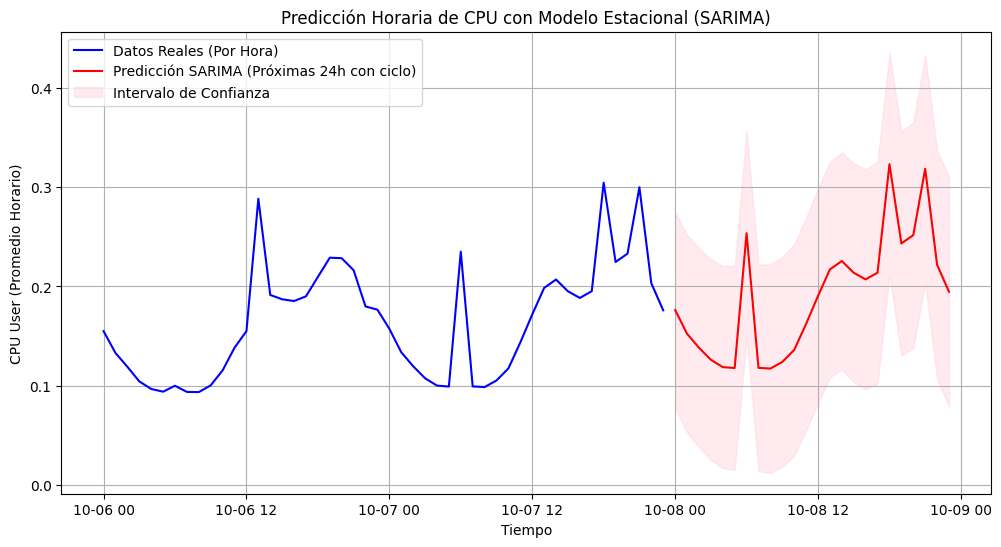

In [5]:
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Agrupar los datos por hora (media)
df_hourly = df.set_index('time').resample('h').mean().ffill()

# Ajustar un modelo SARIMA con estacionalidad diaria (periodo = 24 horas)
# Usamos un orden simple no estacional (1, 1, 1) y un orden estacional (1, 1, 1, 24)
model = SARIMAX(df_hourly['cpu_user'],
                order=(1, 1, 1),
                seasonal_order=(1, 1, 1, 24),
                enforce_stationarity=False,
                enforce_invertibility=False)
results = model.fit(disp=False)

# Predecir las próximas 24 horas
forecast_steps = 24
forecast = results.get_forecast(steps=forecast_steps)
forecast_df = forecast.summary_frame()

# Graficar los datos reales e incluir la predicción estacional futura
plt.figure(figsize=(12, 6))
plt.plot(df_hourly.index, df_hourly['cpu_user'], label='Datos Reales (Por Hora)', color='blue')
plt.plot(forecast_df.index, forecast_df['mean'], label='Predicción SARIMA (Próximas 24h con ciclo)', color='red')
plt.fill_between(forecast_df.index, forecast_df['mean_ci_lower'], forecast_df['mean_ci_upper'], color='pink', alpha=0.3, label='Intervalo de Confianza')

plt.title('Predicción Horaria de CPU con Modelo Estacional (SARIMA)')
plt.xlabel('Tiempo')
plt.ylabel('CPU User (Promedio Horario)')
plt.legend()
plt.grid(True)
plt.show()

In [6]:
import numpy as np

# Obtener los valores ajustados (predicciones dentro de la muestra histórica)
valores_ajustados = results.fittedvalues
valores_reales = df_hourly['cpu_user']

# Evitar división por cero si existieran valores exactamente iguales a cero
mask = valores_reales != 0

# Calcular el MAPE (Mean Absolute Percentage Error)
mape = np.mean(np.abs((valores_reales[mask] - valores_ajustados[mask]) / valores_reales[mask])) * 100

print(f"El MAPE (Error Porcentual Absoluto Medio) del modelo es: {mape:.2f}%")

El MAPE (Error Porcentual Absoluto Medio) del modelo es: 15.21%


In [7]:
import pickle

# Guardar el modelo SARIMA entrenado en un archivo pickle
file_name = 'modelo_sarima_cpu.pkl'
with open(file_name, 'wb') as file:
    pickle.dump(results, file)

print(f"El modelo se ha guardado correctamente como '{file_name}'")

El modelo se ha guardado correctamente como 'modelo_sarima_cpu.pkl'
